## Libraries

In [1]:
import pandas as pd
import numpy as np

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

# PCA

## Preliminary phase (choosing number of components)

I have to convert dates into integers for the PCA to work

In [2]:
df = pd.read_csv("processed_data/feature_engineering_seasons.csv")
df["season_start"] = pd.to_datetime(df["season_start"]).dt.dayofyear
df["season_end"] = pd.to_datetime(df["season_end"]).dt.dayofyear
df["season_duration"] = df["season_duration"].str.replace("days","").str.strip().astype(int)
df["returns_end"] = pd.to_datetime(df["returns_end"]).dt.dayofyear

PCA does not accept null values, so I have to fill Na

In [3]:
df["returns_end"] = df["returns_end"].fillna(0).astype(int)

First, for the PCA I have to normalize the data.\
The formula is

$$
z_i = \frac{x_i-\mu}{\sigma}
$$

and transforms a variable so that the mean is 0 and the standard deviation = 1. This way, PCA and clustering are not affected by numeric differences between variables.\
$x_i$ is a single observation (one place and one year), while $\mu$ and $\sigma$ are calculated on the whole population of data

In [4]:
features = df.columns.to_list()[2:]

scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features])

Before the PCA, I have to create a column for each year, with a row for each municipality.\
This way, the PCA can analyze the components of variation between years considering all years together instead of having a row for each year 

In [5]:
df_pivot = df_scaled.pivot(
    index="municipality",
    columns="year",
    values=features
)

df_pivot.columns = [
    f"{indicator}_{year}"
    for indicator, year in df_pivot.columns
]

Finally, I can perform the PCA

In [6]:
pca = PCA()
X_pca = pca.fit_transform(df_pivot)

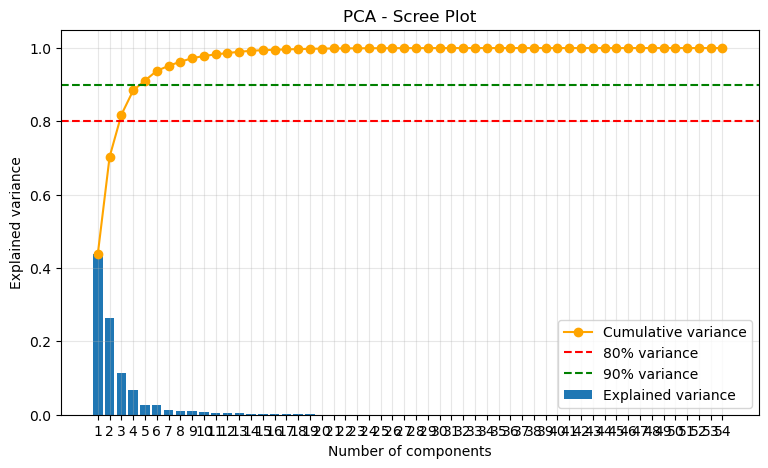

In [7]:
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    label="Explained variance",
    )

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="orange",
    label="Cumulative variance"
)

plt.axhline(
    y=0.80,
    color="red",
    linestyle="--",
    label="80% variance"
)

plt.axhline(
    y=0.90,
    color="green",
    linestyle="--",
    label="90% variance"
)

plt.xlabel("Number of components")
plt.ylabel("Explained variance")
plt.title("PCA - Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()

plt.show()

The main rules for choosing the number of components are:
* cumulative variance > 80-90%
* elbow method (plateau)
* interpretability of results

In [8]:
pd.DataFrame({
    "Eigenvalue": pca.explained_variance_,
    "Explained variance": pca.explained_variance_ratio_,
    "Cumulative variance": np.cumsum(
        pca.explained_variance_ratio_
    )
}, index=[
    f"PC{i+1}" for i in range(pca.n_components_)
]).head()

,Eigenvalue,Explained variance,Cumulative variance
PC1,20.169709,0.438743,0.438743
PC2,12.165061,0.264621,0.703364
PC3,5.278852,0.114829,0.818193
PC4,3.041446,0.066159,0.884352
PC5,1.243418,0.027048,0.911400


Another rule (Kaiser's rule) suggests to keep components with Eigenvalues > 1.\
This means that all the first 4 components must be kept (even the 5th, actually). However, the results would become harder to interpret

Loadings = how much original variables contribute to principal components

In [9]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=df_pivot.columns,
    columns=[
        f"PC{i+1}"
        for i in range(pca.n_components_)
    ]
)

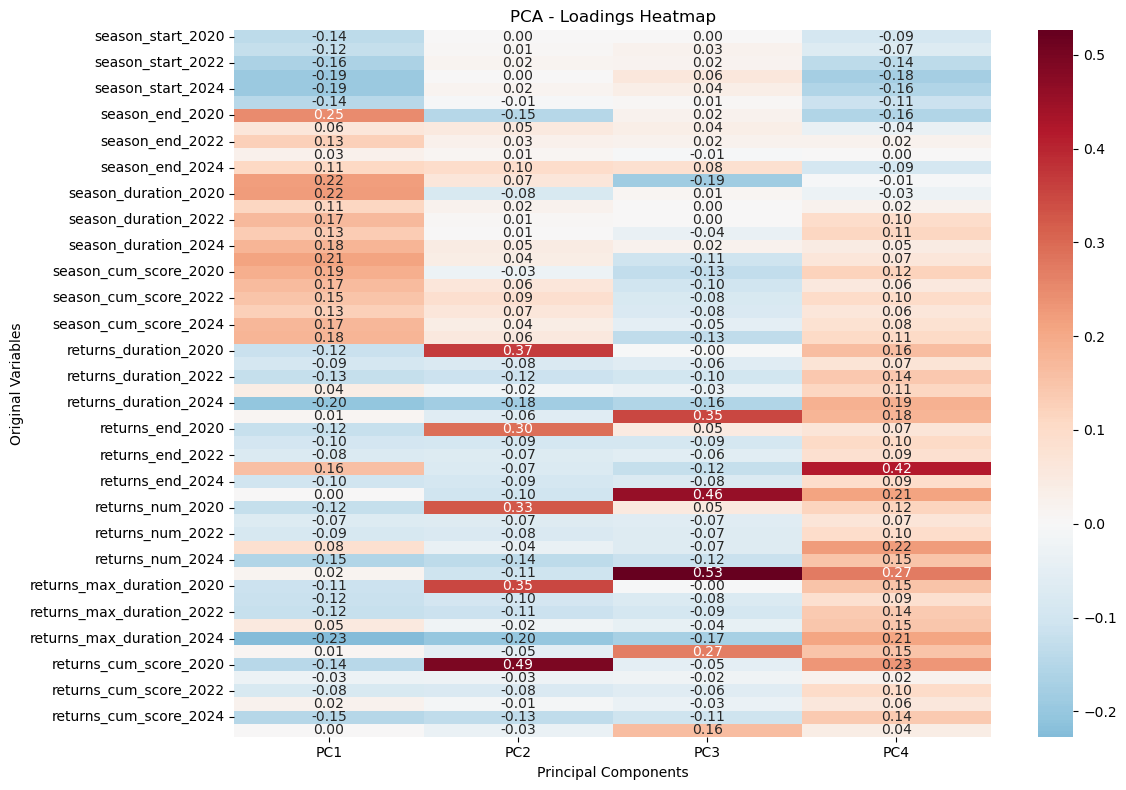

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    loadings.iloc[:, :4],
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)

plt.title("PCA - Loadings Heatmap")
plt.xlabel("Principal Components")
plt.ylabel("Original Variables")

plt.tight_layout()
plt.show()

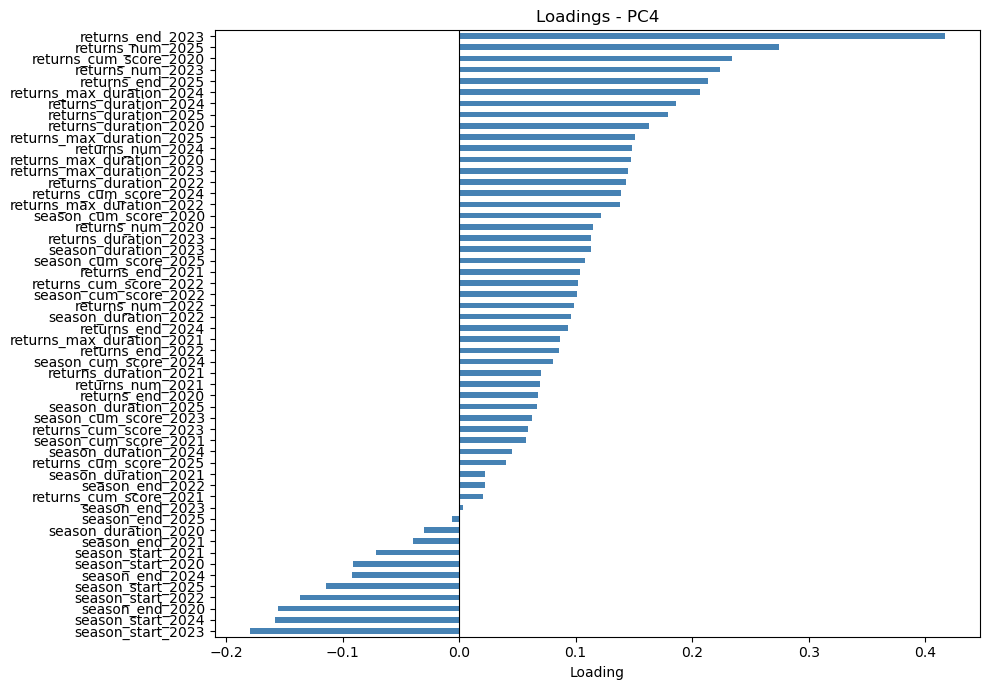

In [11]:
loadings["PC4"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Loadings - PC4")
plt.xlabel("Loading")
plt.tight_layout()
plt.show()

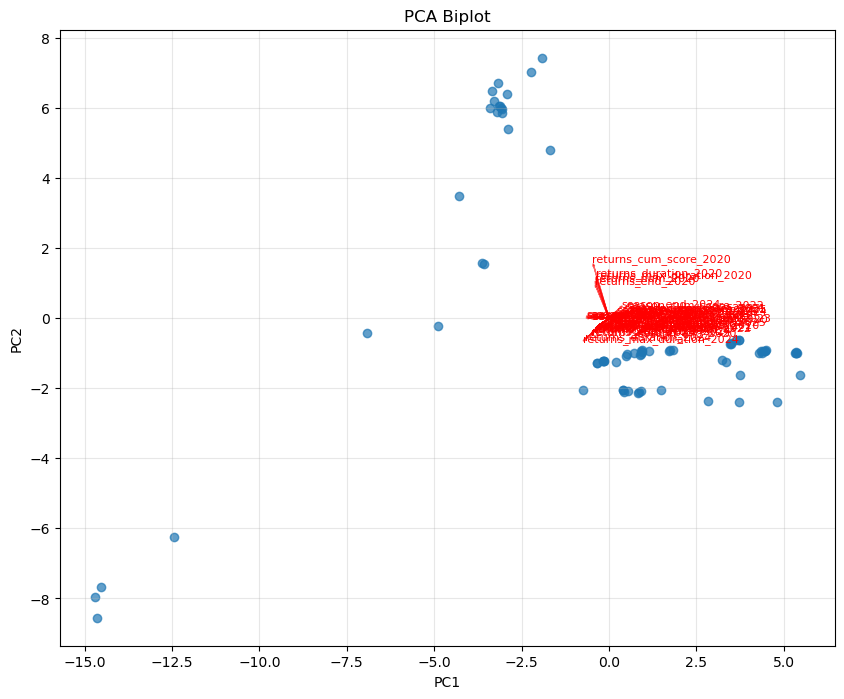

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))

# Località
ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.7
)

# Loadings
scale = 3

for i, variable in enumerate(loadings.index):
    ax.arrow(
        0, 0,
        loadings.iloc[i, 0] * scale,
        loadings.iloc[i, 1] * scale,
        color="red",
        alpha=0.6,
        head_width=0.05
    )

    ax.text(
        loadings.iloc[i, 0] * scale * 1.1,
        loadings.iloc[i, 1] * scale * 1.1,
        variable,
        color="red",
        fontsize=8
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA Biplot")

plt.grid(alpha=0.3)
plt.show()

Biplot shows:
* Municipalities in the bidimensional space of the first 2 components
* Original variable (vectors)


The interpretation is:
* Long arrows: variable well represented on the PC1-PC2 space
* Close arrows: positive correlation between variables
* Opposite arrows: negative correlation
* Orthogonal arrows: little correlation

Since it's complicated to analyze 54 indicators (9 features * 6 years), they will be aggregated (1 feature for all 6 years).

The aggregation is Root Mean Squares (RMS)

$$
L_{f,k}^{\mathrm{agg}} =
\sqrt{
\frac{1}{N}
\sum_{t=1}^{N}
L_{f,t,k}^{2}
}
$$

* $L_{f,k}^{\mathrm{agg}}$ is the aggregated loading of feature f, on the component k
* $L_{f,t,k}$ is the loading of feature f, in the year t, on the component k
* $N$ is the number of years

In this case, the power of 2 does not account for positive/negative correlations but instead measures the average intensity of the association between the feature and the principal component (the direction of the association is lost) 

In [ ]:
aggregated = {}

for feature in features:

    cols = [
        col for col in loadings.index
        if col.startswith(feature + "_")
    ]

    aggregated[feature] = np.sqrt(
        (loadings.loc[cols] ** 2).mean()
    )

loadings_aggregated = pd.DataFrame(
    aggregated
).T                                                 #transpose

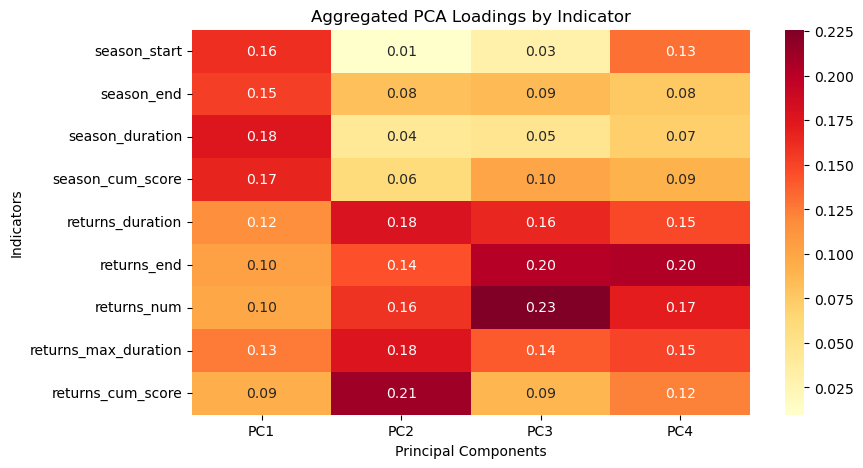

In [14]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    loadings_aggregated.iloc[:, :4],
    annot=True,
    cmap="YlOrRd",
    fmt=".2f"
)

plt.title("Aggregated PCA Loadings by Indicator")
plt.xlabel("Principal Components")
plt.ylabel("Indicators")

plt.show()

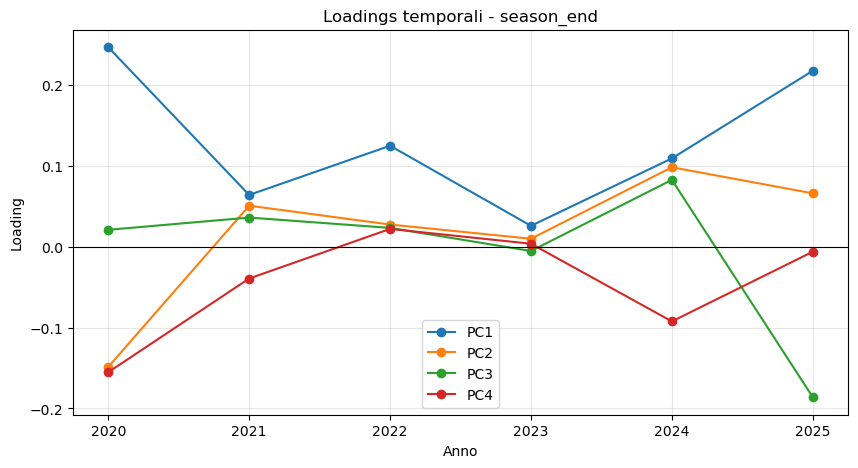

In [15]:
feature = "season_end"

cols = [
    col for col in loadings.index
    if col.startswith(feature + "_")
]

data = loadings.loc[cols, ["PC1", "PC2", "PC3", "PC4"]].copy()

data["year"] = [
    int(col.split("_")[-1])
    for col in data.index
]

data = data.set_index("year")

data.plot(
    marker="o",
    figsize=(10, 5)
)

plt.title(f"Loadings temporali - {feature}")
plt.xlabel("Anno")
plt.ylabel("Loading")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(alpha=0.3)
plt.show()

Summing up:
* PC1 is correlated with season
* PC2 is correlated with returns
    * mostly 2020
* PC3 is also correlated with returns
    * mostly 2025
* PC4 is also correlated with returns
    * this time with contribution of the season

## Actual PCA

In [16]:
pca = PCA(n_components=4)
X_pca = pca.fit_transform(df_pivot)

# Clustering

## K-means

### Choosing number of clusters

Two complementary criteria were adopted:
* Elbow method
    * analyzes the reduction of the Within Clusters Sum of Squares (WCSS, or *inertia*) with the increase of $k$
    * the elbow is the point where adding more clusters does not improve clustering
* Silhouette Score
    * measure how much each observation is similar to the other elements in its cluster, with respect to the elements in other clusters
        * cohesion = $a(i)$ is the average distance between an observation and the others within the cluster
        * separation = $b(i)$ is the min average distance betwenn an observation and the observations of another cluster
    * Values between -1 and +1 (high values mean high internal cohesion and good separation between clusters)
        * s close to 1 = observation close to its cluster and distant from other clusters
        * s close to 0 = observation at the border between clusters
        * s < 0 = observation closer to another cluster
$$
s(i) = \frac{b(i)-a(i)}{\max(a(i),b(i))}
$$



The final choice of $k$ is influenced by both criteria

Elbow method

c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.p

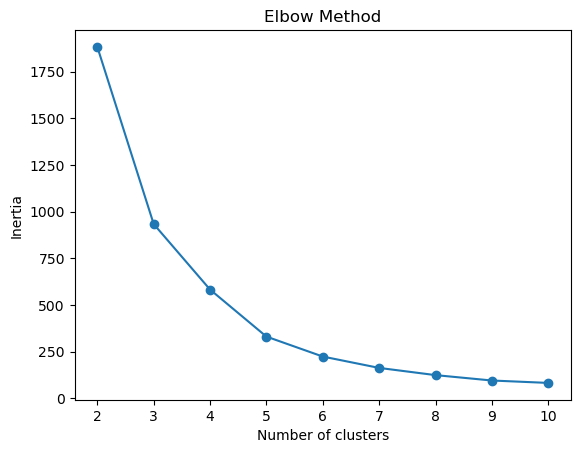

In [ ]:
inertias = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init means that the algorithm is run 10 times with different initial positions of the clusters, and the final inertia is the lowest
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

Silhouette score

In [18]:
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    print(f'Cluster: {k}, Silhouette Score: {score:.3f}')

c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.p

Cluster: 2, Silhouette Score: 0.513
Cluster: 3, Silhouette Score: 0.569
Cluster: 4, Silhouette Score: 0.544
Cluster: 5, Silhouette Score: 0.642
Cluster: 6, Silhouette Score: 0.669
Cluster: 7, Silhouette Score: 0.698


c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Cluster: 8, Silhouette Score: 0.711
Cluster: 9, Silhouette Score: 0.686
Cluster: 10, Silhouette Score: 0.675


### Visualizing

K-means clustering

In [19]:
# Clustering
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)

clusters_kmeans = kmeans.fit_predict(X_pca)

c:\Users\Computer\miniconda3\envs\Boolean\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


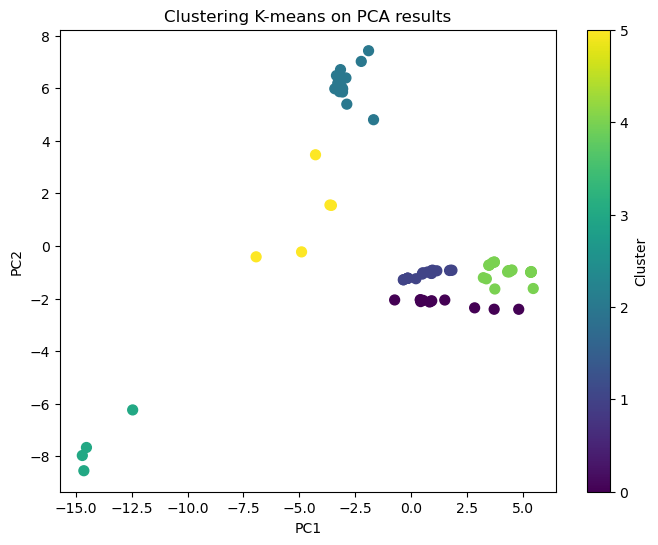

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_kmeans,
    cmap='viridis',
    s=50
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clustering K-means on PCA results')
plt.colorbar(label='Cluster')

plt.show()

## Agglomerative clustering

* Hierarchical algorithm, building a hierarchy of groups through a dendrogram.
* *bottom-up* algorithm (many separate observations are progressively grouped)
    * single observations (clusters = observations)
    * 2 closest clusters are grouped forming a bigger cluster
    * again, until a single cluster with all observations is found
* the distance between clusters is calculated with the *linkage* parameter
    * single = min distance between points in the two clusters
    * complete = max distance between points in the two clusters
    * average
    * ward = minimizes the increase in the intra-cluster variance (generates compact and uniform clusters)

### Choosing number of clusters

Silhouette score

In [21]:
silhouette_scores = []

for k in range(2, 11):

    clustering = AgglomerativeClustering(n_clusters=k)

    clusters = clustering.fit_predict(X_pca)

    score = silhouette_score(X_pca, clusters)

    silhouette_scores.append(score)

    print(f'Cluster: {k}, Silhouette Score: {score:.3f}')

Cluster: 2, Silhouette Score: 0.513
Cluster: 3, Silhouette Score: 0.569
Cluster: 4, Silhouette Score: 0.537
Cluster: 5, Silhouette Score: 0.632
Cluster: 6, Silhouette Score: 0.669
Cluster: 7, Silhouette Score: 0.698
Cluster: 8, Silhouette Score: 0.711
Cluster: 9, Silhouette Score: 0.693
Cluster: 10, Silhouette Score: 0.681


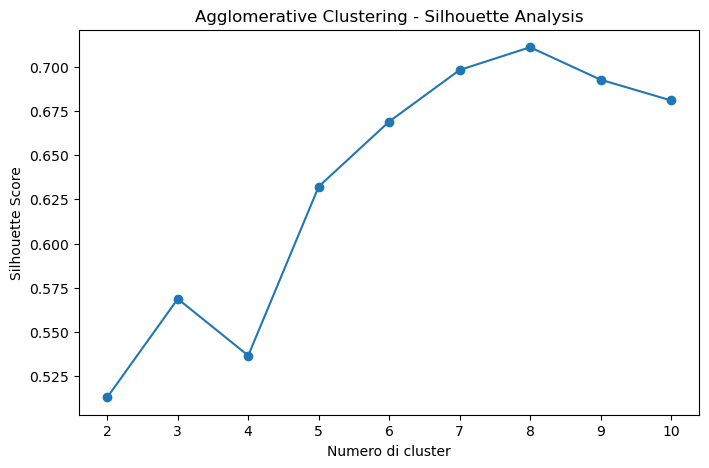

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.xlabel('Clusters')
plt.ylabel('Silhouette Score')
plt.title('Agglomerative Clustering - Silhouette Analysis')

plt.show()

Dendrogram
* Lower leaves are single observations
* Union between branches are cluster groupings
* the height where 2 branches merge is the distance of the union

The most important parameter is the height: if the height is significantly higher than previous groupings, it means that clusters are significantly different

Dendrogramma.

L'idea è individuare i salti più ampi nelle distanze di aggregazione e tagliare il dendrogramma orizzontalmente prima di questi salti.

Ad esempio, se il taglio intercetta 4 rami principali, ottieni 4 cluster.

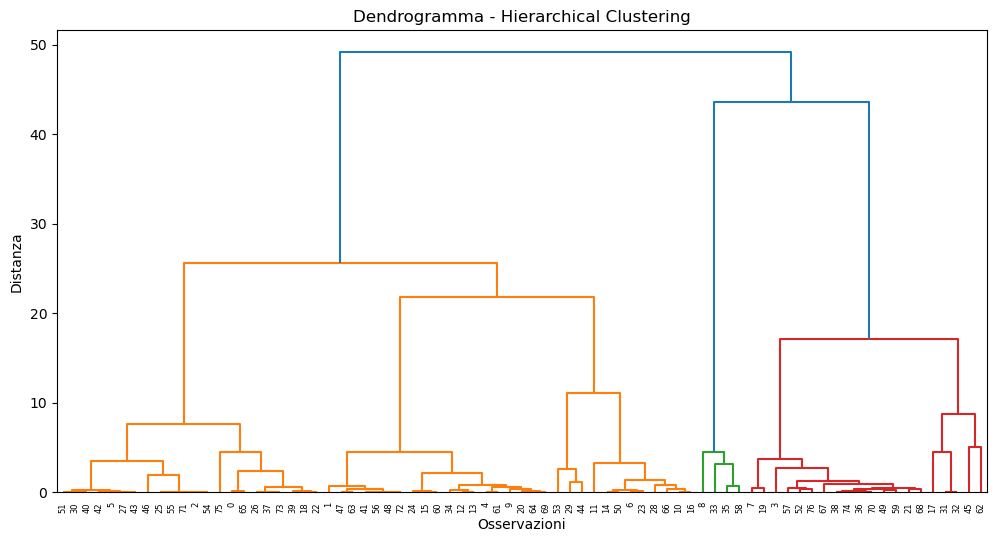

In [ ]:
plt.figure(figsize=(12, 6))

dendrogram = sch.dendrogram(
    sch.linkage(X_pca, method='ward')
)

plt.title('Dendrogram - Hierarchical Clustering')
plt.xlabel('Observations')
plt.ylabel('Distance')
plt.show()

### Visualizing

In [25]:
clustering = AgglomerativeClustering(
    n_clusters=6,
    metric="euclidean",
    linkage="ward"
)

clusters_agglomerative = clustering.fit_predict(X_pca)

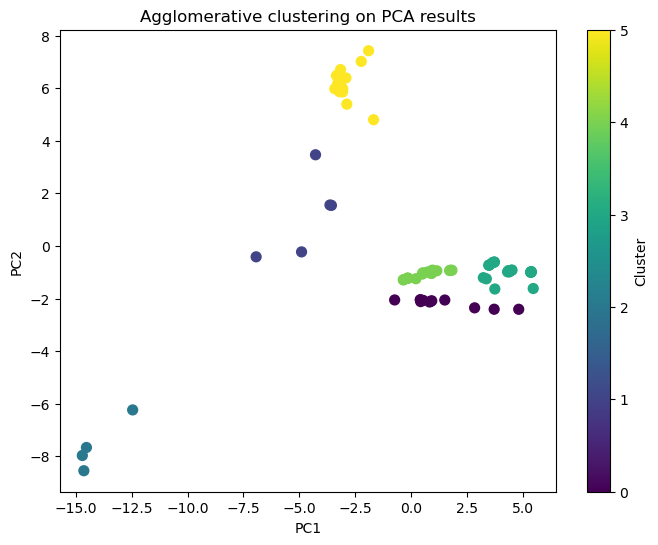

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_agglomerative,
    cmap='viridis',
    s=50
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Agglomerative clustering on PCA results')
plt.colorbar(label='Cluster')

plt.show()

## DBscan

DBSCAN = Density-Based Spatial Clustering of Applications with Noise

DBSCAN is a density-based clustering algorithm. Unlike K-Means and Agglomerative Clustering, it identifies clusters by looking for areas of high point density, separating them from areas of low density.

One of its main advantages is that it can identify clusters of irregular shapes and explicitly detect outliers (observations that do not belong to any cluster).

DBSCAN relies on 2 main concepts:
* Neighbourhood: the area surrounding an observation, defined by a distance threshold.
* Density: the number of observations within that neighbourhood.

It distinguishes 3 types of observations:
* Core points: observations with at least min_samples points within their epsilon neighbourhood.
* Border points: observations that do not satisfy the density requirement themselves but are within the neighbourhood of a core point.
* Noise points: observations that are not assigned to any cluster.

Clusters are formed by connecting density-reachable core points and their associated border points.

DBSCAN requires two parameters: eps and min_samples:
* eps defines the maximum distance between two observations for them to be considered neighbours.
    * $\epsilon = 0.5$ means that two observations are neighbours if their distance is less than or equal to 0.5
    * Too small eps: many observations become noise, and clusters may fragment.
    * Too large eps: different groups may merge into a single cluster.
    * Therefore, the objective is to find a distance threshold that captures meaningful density structures.
* min_samples defines the minimum number of observations required within an epsilon neighbourhood for a point to be considered a core point.
    * $min samples = 4$ means that an observation must have at least four observations in its neighbourhood (including itself) to qualify as a core point.
    * Low min_samples: clusters can form more easily, potentially including sparse structures.
    * High min_samples: the algorithm requires denser groups, potentially classifying more observations as noise.
    * A common starting heuristic is to use at least the dimensionality of the dataset plus one, although the appropriate value depends on the data.

### Choosing parameters

One of the most common approaches is the K-distance graph. The procedure is:
1. Choose a value for min_samples.
2. Calculate the distance from each observation to its k-th nearest neighbour. (k = min_samples - 1, since the point itself is considered part of the min_samples)
3. Sort these distances in ascending order.
4. Plot the sorted distances.
5. Look for an elbow (a point where distances start increasing sharply).

The elbow represents a possible threshold separating observations in relatively dense regions from observations in sparse regions.

The corresponding distance can be used as a candidate value for eps.

A commont starting point for min_samples is d + 1 (number of dimensions used for clustering + 1).
Then I could evaluate 5, 6, 8, 10

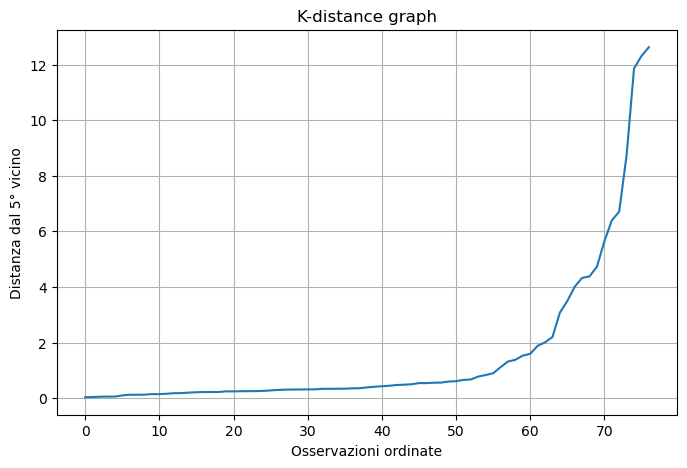

In [ ]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_pca)

distances, indices = neighbors_fit.kneighbors(X_pca)

# Distance from k-th neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)

plt.xlabel('Osservazioni ordinate')
plt.ylabel(f'Distanza dal {min_samples -1}° vicino')
plt.title('K-distance graph')
plt.grid()
plt.show()

1. For each municipality, the algorithm calculates the euclidean distance between the municipality and the other municipalities, sorted in ascending order
2. With min_samples = 5, the 4th sorted distance is chosen (these 4 points could become *core points* of the cluster of the municipality)
3. For every municipality, the distance for becoming a core point is calculated (in the final graph, a point for each municipality is represented)
4. These distances are sorted and represented:
    * on the left, there are observations surrounded by many other observations
    * on the right, there are observations that are far away from others, and need a high epsilon to become a core point

The overall question is: how much do I have to set the epsilon to find at least min_samples observations?

In [ ]:
eps_values = list(np.arange(1, 3.1, 0.5))
min_samples_values = [5, 6]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_pca)

        # Excluding noise (-1) from silhouette
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        noise_percentage = np.mean(~mask) * 100

        if n_clusters >= 2 and mask.sum() > n_clusters:
            score = silhouette_score(
                X_pca[mask],
                labels[mask]
            )
        else:
            score = np.nan

        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'noise_%': noise_percentage,
            'silhouette': score
        })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by='silhouette',
    ascending=False
)

,eps,min_samples,n_clusters,noise_%,silhouette
0,1.0,5,6,25.974026,0.846688
1,1.0,6,5,32.467532,0.839588
2,1.5,5,4,22.077922,0.784645
3,1.5,6,4,22.077922,0.784645
4,2.0,5,4,18.181818,0.773199
5,2.0,6,4,18.181818,0.773199
6,2.5,5,3,16.883117,0.621587
7,2.5,6,3,16.883117,0.621587
8,3.0,5,3,15.584416,0.611125
9,3.0,6,3,15.584416,0.611125


### Visualizing

In [ ]:
dbscan = DBSCAN(eps=1, min_samples=5)

clusters_dbscan = dbscan.fit_predict(X_pca)

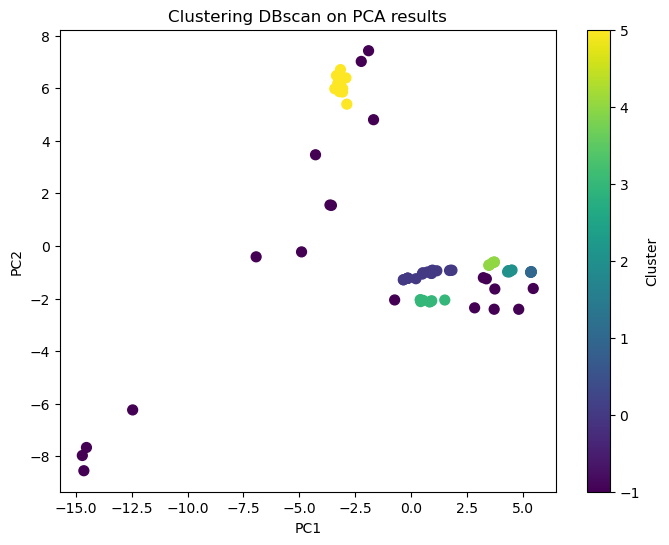

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_dbscan,
    cmap='viridis',
    s=50
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clustering DBscan on PCA results')
plt.colorbar(label='Cluster')

plt.show()

This algorithm is not suitable for this kind of data distribution, since there are no dense clusters with complex geometries that could not be detected with the other algorithms

## Clustering column to the original dataset

The agglomerative and K-means clustering converged to the same results

In [31]:
# Since every municipality is associated with a cluster
df_clusters = pd.DataFrame({
    "municipality": df_pivot.index,
    "cluster": clusters_kmeans
})

# Then I can add the cluster column after a merge with the original DataFrame
df = df.merge(df_clusters, on="municipality", how="left")

In [32]:
df_clusters["cluster"].value_counts().sort_index()

cluster
0    12
1    19
2    15
3     4
4    22
5     5
Name: count, dtype: int64

I tried to visualize in my mind the clusters with my knowledge of the territory, but there was not a perfect relationship with geographical divisions of the region

In [33]:
for cluster in df["cluster"].drop_duplicates().to_list():
    print(f"##### Cluster {cluster} #####")
    print(df.loc[df["cluster"] == cluster, "municipality"].drop_duplicates())

##### Cluster 4 #####
0      Albaredo per San Marco
12          Andalo Valtellino
30                       Bema
108                   Cercino
132                      Cino
150                   Delebio
156                    Dubino
162                       Era
180                   Gordona
222                  Mantello
234                     Mello
240                      Mese
252                  Morbegno
258            Novate Mezzola
276                  Piantedo
306        Prata Camportaccio
324                  Regoledo
330                    Rogolo
390                  Talamona
426                    Traona
438                   Verceia
450        Villa di Chiavenna
Name: municipality, dtype: str
##### Cluster 1 #####
6                  Albosaggia
24                    Ardenno
54            Buglio in Monte
72                  Caspoggio
78        Castello dell'Acqua
90                  Cataeggio
120      Chiesa in Valmalenco
144                     Dazio
204                   Lan

# Visualizing clusters

So, I chose to visualize them in a map

In [34]:
municipalities = pd.read_csv("processed_data/municipalities.csv")

In [37]:
municipalities_clusters = municipalities.merge(df, left_on="name", right_on="municipality", how="left").drop_duplicates("name")[["name", "lat", "lon", "cluster"]]

In [ ]:
# Center: average coordinates
center = [municipalities_clusters["lat"].mean(), municipalities_clusters["lon"].mean()]

m = folium.Map(
    location=center,
    zoom_start=9
)

# Colors for clusters
colors = [
    "red", "blue", "green",
    "purple", "orange", "darkred"
]

for _, row in municipalities_clusters.drop_duplicates("name").iterrows():

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=7,
        color=colors[int(row["cluster"])],
        fill=True,
        fill_opacity=0.7,
        popup=f'{row["name"]} - Cluster {row["cluster"]}'
    ).add_to(m)

m

Interestingly, the clusters almost follow the geographical distribution of municipalities, with some exceptions:
* green cluster = Valchiavenna (west valley) and the region around Tirano
* brown/dark red = Pianazzo in Valchiavenna and the east valley (Sondalo)
* red and blue = split and intersected

In [39]:
m.save("processed_data/clusters_map.html")

In [41]:
municipalities_clusters.to_csv("processed_data/municipalities_clusters.csv", index=False)

# Municipalities per geographical area

For better clarity, I wanted to visualize the regions of the area (Valtellina), from West to East:
* Valchiavenna = valley with a different river from the main valley
* Bassa Valtellina = lower valley, referring to the position relative to the main river of the main valley (including the lateral valley of Valmasino)
* Media Valtellina (Sondriese) = middle valley around Sondrio (including the lateral valley of Valmalenco)
* Media Valtellina Orientale (Tiranese) = middle valley around Tirano (including the lateral valley of Val Grosina) 
* Alta Valtellina : higher valley, where the river originates (including valleys up to Livigno)

In [ ]:
administrative_centers = pd.read_csv("raw_data/administrative_centers.csv", sep=";")
municipalities_per_geographical_area = pd.read_csv("raw_data/municipalities_per_geographical_area.csv")

In [54]:
administrative_centers_per_geographical_area = municipalities_per_geographical_area.merge(administrative_centers, on="Municipality", how="left")

In [60]:
merged = administrative_centers_per_geographical_area.merge(municipalities_clusters, left_on="Administrative center", right_on="name", how="left")

In [ ]:
center = [merged["lat"].mean(), merged["lon"].mean()]

m = folium.Map(
    location=center,
    zoom_start=9
)

colors = {"Valchiavenna" : "red",
          "Bassa Valtellina" : "blue", 
          "Media Valtellina (Sondriese)" : "green",
          "Media Valtellina Orientale (Tiranese)" : "purple", 
          "Alta Valtellina" : "orange"
}

for _, row in merged.drop_duplicates("Municipality").iterrows():

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=7,
        color=colors.get(row["Geographical_area"], "gray"),
        fill=True,
        fill_opacity=0.7,
        popup=f'{row["Municipality"]} - Area {row["Geographical_area"]}'
    ).add_to(m)

m